## Carpeta de trabajo
Se monta Drive y se trabaja en la carpeta del proyecto: lo que el cuaderno lee y guarda queda ahí. Antes, la carpeta compartida debe tener un acceso directo en Mi unidad.

In [1]:
import os, subprocess

# Dónde están datos/ y resultados/:
#  1) en Colab, si existe la carpeta compartida del equipo en Drive, se usa esa;
#  2) en Colab sin esa carpeta (p. ej. abierto desde GitHub), se clona el repositorio;
#  3) fuera de Colab, se usa la raíz del repositorio aunque el notebook se abra desde notebooks/.
CARPETA = "/content/drive/MyDrive/Evalucion 3 y Examen"   # acceso directo del equipo en Mi unidad
REPO = "https://github.com/LeonardoAmundarain/caso5-riesgo-coronario.git"

try:
    from google.colab import drive
    EN_COLAB = True
except ModuleNotFoundError:
    EN_COLAB = False

if EN_COLAB:
    try:
        drive.mount("/content/drive")
    except Exception:
        pass
    if os.path.isdir(CARPETA):
        os.chdir(CARPETA)
    else:
        destino = "/content/caso5-riesgo-coronario"
        if not os.path.isdir(destino):
            subprocess.run(["git", "clone", "-q", REPO, destino], check=True)
        os.chdir(destino)
elif not os.path.isdir("datos") and os.path.isdir(os.path.join("..", "datos")):
    os.chdir("..")

os.makedirs("datos", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

print("Carpeta:", os.getcwd())
for f in ['datos/framingham_teaching.csv', 'datos/ens_homologada.csv']:
    print(f, "presente:", os.path.exists(f))

Mounted at /content/drive
Carpeta: /content/drive/.shortcut-targets-by-id/1Y-XrKLmj3y7vuHBzmQH9X-DvE-h6v7OV/Evalucion 3 y Examen
datos/framingham_teaching.csv presente: True
datos/ens_homologada.csv presente: True


##Cargar los datos

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fram = pd.read_csv("datos/framingham_teaching.csv")
ens = pd.read_csv("datos/ens_homologada.csv")

print(fram.shape, ens.shape)

(11627, 39) (2242, 18)


##Armar la cohorte de Framingham y la etiqueta

In [3]:
# Examen basal y sin enfermedad coronaria previa
base = fram[(fram.PERIOD == 1) & (fram.PREVCHD == 0)].copy()

# Etiqueta: enfermedad coronaria dentro de 10 años
base["chd_10a"] = ((base.ANYCHD == 1) & (base.TIMECHD <= 3652)).astype(int)

print(len(base), base.chd_10a.sum(), round(base.chd_10a.mean() * 100, 1))

4240 379 8.9


In [4]:
corto = (base.chd_10a == 0) & (base.TIMECHD < 3652)
murio = (base.DEATH == 1) & (base.TIMEDTH < 3652)

print("Sin evento y con seguimiento < 10 años:", corto.sum())
print("  murieron por otra causa:", (corto & murio).sum())
print("  perdidos del seguimiento:", (corto & ~murio).sum())

# Los que murieron por otra causa quedan en 0; los perdidos se excluyen
base = base[~(corto & ~murio)]
print(len(base), base.chd_10a.sum(), round(base.chd_10a.mean() * 100, 1))

Sin evento y con seguimiento < 10 años: 265
  murieron por otra causa: 249
  perdidos del seguimiento: 16
4224 379 9.0


##Dejar solo los predictores comunes

In [5]:
PRED = ["AGE", "SEX", "SYSBP", "DIABP", "TOTCHOL", "GLUCOSE", "BMI",
        "HEARTRTE", "CURSMOKE", "CIGPDAY", "DIABETES", "BPMEDS"]

fram_c = base[["RANDID"] + PRED + ["chd_10a"]].rename(columns={"RANDID": "ID"})

print(fram_c.shape)
print("IDs repetidos:", fram_c.ID.duplicated().sum())

(4224, 14)
IDs repetidos: 0


##Revisar la calidad de los datos

In [6]:
#  Nulos en los dos datasets
nulos = pd.DataFrame({"Framingham": fram_c[PRED].isna().sum(),
                      "ENS": ens[PRED].isna().sum()})
print(nulos[nulos.sum(axis=1) > 0])

#  Rangos
print(fram_c[PRED].describe().T[["min", "50%", "max"]])

#  Valores fuera de lo clínicamente posible
limites = {"SYSBP": (70, 300), "DIABP": (30, 160), "TOTCHOL": (80, 700),
           "GLUCOSE": (30, 600), "BMI": (12, 70), "HEARTRTE": (30, 220)}
for col, (lo, hi) in limites.items():
    f = (~fram_c[col].between(lo, hi) & fram_c[col].notna()).sum()
    e = (~ens[col].between(lo, hi) & ens[col].notna()).sum()
    print(f"{col}: Framingham {f} | ENS {e}")

          Framingham  ENS
TOTCHOL           49   80
GLUCOSE          384  137
BMI               19    7
HEARTRTE           1    0
CIGPDAY           29    0
BPMEDS            53    2
             min     50%    max
AGE        32.00   49.00   70.0
SEX         1.00    2.00    2.0
SYSBP      83.50  128.00  295.0
DIABP      48.00   82.00  142.5
TOTCHOL   107.00  234.00  696.0
GLUCOSE    40.00   78.00  394.0
BMI        15.54   25.41   56.8
HEARTRTE   44.00   75.00  143.0
CURSMOKE    0.00    0.00    1.0
CIGPDAY     0.00    0.00   70.0
DIABETES    0.00    0.00    1.0
BPMEDS      0.00    0.00    1.0
SYSBP: Framingham 0 | ENS 0
DIABP: Framingham 0 | ENS 0
TOTCHOL: Framingham 0 | ENS 0
GLUCOSE: Framingham 0 | ENS 0
BMI: Framingham 0 | ENS 0
HEARTRTE: Framingham 0 | ENS 0


##Fumadores ocasionales de la ENS

A los fumadores ocasionales la ENS no les preguntó cuántos cigarros fuman. Se les asigna un valor fijo y la decisión queda escrita

In [7]:
CIG_OCASIONAL = 1  # decisión del grupo: 1 cigarro al día

ocas = (ens.CURSMOKE == 1) & ens.CIGPDAY.isna()
print("Fumadores sin cigarros/día:", ocas.sum())

ens.loc[ocas, "CIGPDAY"] = CIG_OCASIONAL
print("Nulos que quedan en CIGPDAY:", ens.CIGPDAY.isna().sum())

Fumadores sin cigarros/día: 0
Nulos que quedan en CIGPDAY: 0


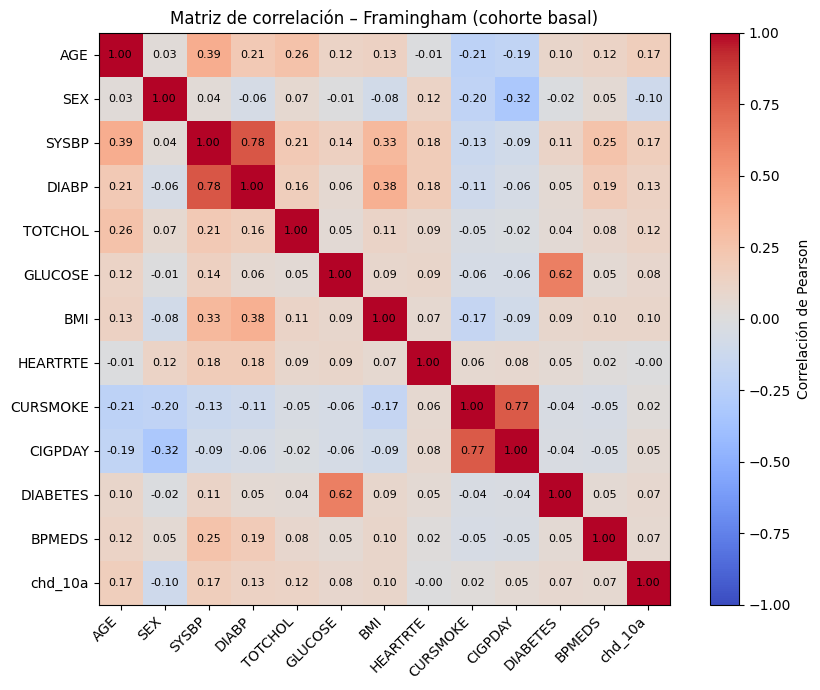

In [8]:
cols = PRED + ["chd_10a"]
corr = fram_c[cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)

# Valor de la correlación dentro de cada celda
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación – Framingham (cohorte basal)")
plt.tight_layout()
plt.show()

SYSBP y DIABP: las dos son presión, así que casi miden lo mismo.

CURSMOKE y CIGPDAY: un no fumador siempre tiene 0 cigarros.

##Imputación
Tratamiento de nulos. Los nulos se imputan con la mediana en las variables continuas, porque es robusta a valores extremos como la PAS de 295 o la glucosa de 478, y con la moda en las binarias. El imputador se define aquí pero no se ajusta: la parte 2 lo incluye dentro del Pipeline, para que las medianas se calculen solo con el entrenamiento de cada pliegue y no haya fuga de datos.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

CONT = ["AGE", "SYSBP", "DIABP", "TOTCHOL", "GLUCOSE", "BMI", "HEARTRTE", "CIGPDAY"]
BIN = ["SEX", "CURSMOKE", "DIABETES", "BPMEDS"]

imputador = ColumnTransformer([
    ("cont", SimpleImputer(strategy="median"), CONT),
    ("bin", SimpleImputer(strategy="most_frequent"), BIN),
])

##EDA

In [10]:
fram_c["tramo"] = pd.cut(fram_c.AGE, [31, 44, 54, 64, 70],
                         labels=["32-44", "45-54", "55-64", "65-70"])

print(fram_c.groupby("SEX").chd_10a.agg(["count", "mean"]))       # 1 = hombre, 2 = mujer
print(fram_c.groupby("tramo", observed=True).chd_10a.agg(["count", "mean"]))

     count      mean
SEX                 
1.0   1813  0.123552
2.0   2411  0.064289
       count      mean
tramo                 
32-44   1417  0.040226
45-54   1490  0.087919
55-64   1150  0.143478
65-70    167  0.155689


In [11]:
print(fram_c.groupby("chd_10a")[PRED].mean().T.round(1))

chd_10a       0      1
AGE        49.2   54.1
SEX         1.6    1.4
SYSBP     131.2  144.0
DIABP      82.4   87.7
TOTCHOL   235.0  254.4
GLUCOSE    81.4   88.0
BMI        25.7   27.1
HEARTRTE   75.9   75.7
CURSMOKE    0.5    0.5
CIGPDAY     8.8   10.8
DIABETES    0.0    0.1
BPMEDS      0.0    0.1


In [12]:
def media_pond(s, w):
    m = s.notna()
    return np.average(s[m], weights=w[m])

# SEX pasa a "es mujer" para que la media sea un porcentaje
f = fram_c[PRED].assign(SEX=fram_c.SEX.eq(2))
e = ens[PRED].assign(SEX=ens.SEX.eq(2))

perfil = pd.DataFrame({
    "Framingham": f.mean(),
    "ENS (ponderada)": [media_pond(e[c].astype(float), ens.PESO) for c in PRED],
}, index=PRED).round(2)
print(perfil)

          Framingham  ENS (ponderada)
AGE            49.60            48.17
SEX             0.57             0.52
SYSBP         132.34           124.35
DIABP          82.89            76.35
TOTCHOL       236.74           187.42
GLUCOSE        81.97            98.41
BMI            25.81            29.42
HEARTRTE       75.87            67.01
CURSMOKE        0.49             0.36
CIGPDAY         8.98             3.58
DIABETES        0.03             0.13
BPMEDS          0.03             0.22


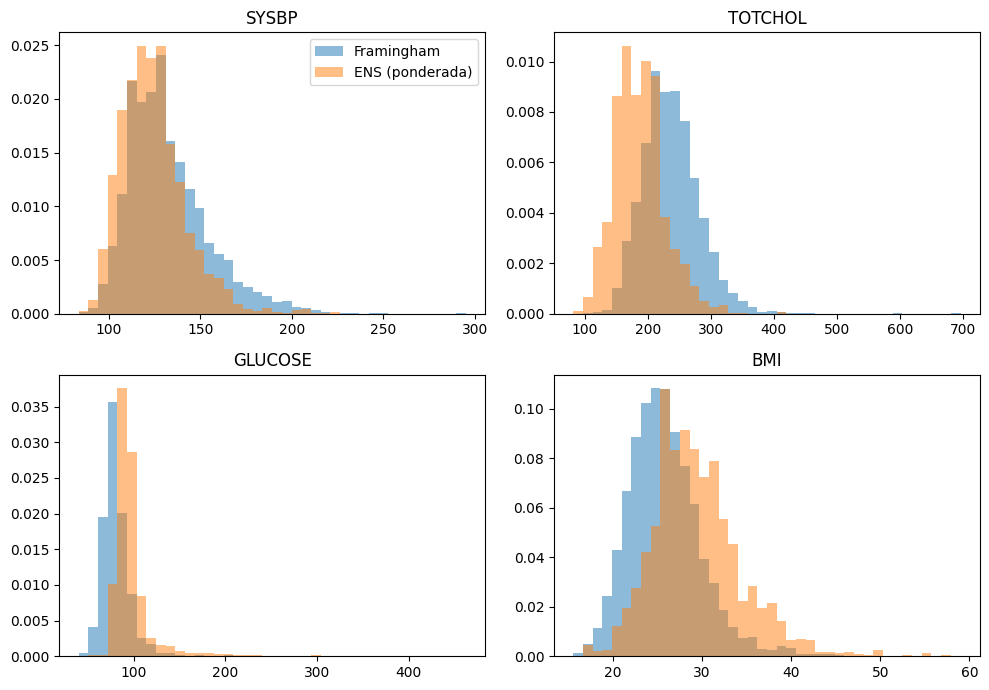

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, ["SYSBP", "TOTCHOL", "GLUCOSE", "BMI"]):
    bins = np.histogram_bin_edges(pd.concat([fram_c[col], ens[col]]).dropna(), 40)
    ax.hist(fram_c[col].dropna(), bins, density=True, alpha=0.5, label="Framingham")
    m = ens[col].notna()
    ax.hist(ens.loc[m, col], bins, weights=ens.loc[m, "PESO"],
            density=True, alpha=0.5, label="ENS (ponderada)")
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [14]:
for col in CONT:
    lo, hi = fram_c[col].min(), fram_c[col].max()
    m = ens[col].notna()
    fuera = ~ens.loc[m, col].between(lo, hi)
    pct = np.average(fuera, weights=ens.loc[m, "PESO"]) * 100
    print(f"{col}: {pct:.1f} % fuera de [{lo}, {hi}]")

AGE: 0.0 % fuera de [32.0, 70.0]
SYSBP: 0.0 % fuera de [83.5, 295.0]
DIABP: 0.0 % fuera de [48.0, 142.5]
TOTCHOL: 0.5 % fuera de [107.0, 696.0]
GLUCOSE: 0.2 % fuera de [40.0, 394.0]
BMI: 0.0 % fuera de [15.54, 56.8]
HEARTRTE: 0.1 % fuera de [44.0, 143.0]
CIGPDAY: 0.4 % fuera de [0.0, 70.0]


In [15]:
fram_c.drop(columns="tramo").to_csv("datos/framingham_cohorte.csv", index=False)
ens.to_csv("datos/ens_homologada.csv", index=False)